# Week4_ex4 — DC power flow, PTDF and LODF: N-1 screening against AC N-1

Reproduces Problems 6.59 and 6.60 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.), with the case Problem6_59: a lossless seven-bus system solved with the DC approximation. The B matrix and angles of 6.59, the 6.60 generator increase that loads line 1-3 to its rating, then the same sensitivities turned into a full N-1 screen and checked against AC power flow.

![PowerWorld one-line](Images/Week4_ex4_result_image.png)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp

# 1. Case data, PowerWorld results and helpers are in case7dc.py next to this notebook
from case7dc import (BUSES, GENS, LINE_NAMES, LINES, LOADS, PW, RATING, S_BASE, SLACK_BUS, build_case, compare,
                     dc_flows, dc_loading, measure, residual_band, state_rows, summarize)

IMG = Path("Images")
IMG.mkdir(exist_ok=True)

In [2]:
# 2. DC base case against the saved PowerWorld solution (DC approximation, resistance ignored, no loss compensation)
base = build_case()
check = compare(state_rows(base, residual_band(build_case, measure), "Problem6_59"))
summarize(check)

,Group,Source,Rows,Max abs diff,Smallest margin,All pass
0,Bus angle,Problem6_59,7,2.421436e-07,0.000002,True
1,Line flow,Problem6_59,11,4.923254e-03,0.000082,True
2,Slack unit,Problem6_59,1,2.842171e-14,0.000025,True


In [3]:
# 3. Problem 6.59 (a): B from the line reactances with the slack row and column removed, and P in pu
buses = [b for b, *_ in BUSES if b != SLACK_BUS]
A = np.zeros((len(LINES), len(BUSES)))                       # branch-bus incidence, from = +1, to = -1
for k, (f, t, *_) in enumerate(LINES):
    A[k, f - 1], A[k, t - 1] = 1.0, -1.0
x = np.array([l[3] for l in LINES])
Ar = A[:, [b - 1 for b in buses]]
B = Ar.T @ np.diag(1 / x) @ Ar                               # B_ii = sum 1/x, B_ij = -sum 1/x of parallel lines

gen = {b: p for b, *_, p in GENS}
load = {b: mw for b, mw, _ in LOADS}
P = np.array([(gen.get(b, 0.0) - load.get(b, 0.0)) / S_BASE for b in buses])

# pandapower builds the same matrix internally
lookup = base._pd2ppc_lookups["bus"]
idx = [lookup[b] for b in buses]
Bpp = base._ppc["internal"]["Bbus"].toarray()[np.ix_(idx, idx)]
assert np.abs(B - Bpp).max() < 1e-9

display(pd.DataFrame(B, index=buses, columns=buses).round(4))
pd.Series(P, index=buses, name="P [pu]").round(7).to_frame().T

,1,2,3,4,5,6
1,20.8333,-16.6667,-4.1667,0.0000,0.0000,0.0000
2,-16.6667,52.7778,-5.5556,-5.5556,-8.3333,-16.6667
3,-4.1667,-5.5556,43.0556,-33.3333,0.0000,0.0000
4,0.0000,-5.5556,-33.3333,43.0556,-4.1667,0.0000
5,0.0000,-8.3333,0.0000,-4.1667,29.1667,0.0000
6,0.0000,-16.6667,0.0000,0.0000,0.0000,25.0000


,1,2,3,4,5,6
P [pu],1.601345,1.098655,-1.1,-0.3,-1.3,0.000117


In [4]:
# 4. Problem 6.59 (b): theta = B^-1 P, against the PowerWorld one-line and pandapower's DC solve
theta = np.degrees(np.linalg.solve(B, P))
angles = pd.DataFrame({"B^-1 P [deg]": theta, "pandapower [deg]": base.res_bus.va_degree[buses].to_numpy(),
                       "PowerWorld [deg]": [PW["va"][b - 1] for b in buses]}, index=buses)
assert np.abs(angles.iloc[:, 0] - angles.iloc[:, 1]).max() < 1e-9
angles["Abs diff to PW"] = (angles.iloc[:, 0] - angles.iloc[:, 2]).abs()
angles.round(7)

,B^-1 P [deg],pandapower [deg],PowerWorld [deg],Abs diff to PW
1,7.678600,7.678600,7.678600,1.000000e-07
2,4.201150,4.201150,4.201150,0.000000e+00
3,-0.431670,-0.431670,-0.431670,2.000000e-07
4,-0.326829,-0.326829,-0.326829,2.000000e-07
5,-1.400116,-1.400116,-1.400116,1.000000e-07
6,2.801034,2.801034,2.801035,1.000000e-07


In [5]:
# 5. Problem 6.60: PTDF of line 1-3 for MW injected at bus 1 and absorbed by the slack.
#    X = B^-1 with a zero row and column for the slack; PTDF[l, i] = (X[from_l, i] - X[to_l, i]) / x_l
X = np.zeros((len(BUSES), len(BUSES)))
X[np.ix_([b - 1 for b in buses], [b - 1 for b in buses])] = np.linalg.inv(B)
PTDF = np.diag(1 / x) @ A @ X                                # lines x buses, slack column zero

l13 = LINE_NAMES.index("1-3-1")
f0 = dc_flows(build_case())
ptdf = PTDF[l13, 0]
answer = pd.DataFrame({
    "Flow 1-3 [MW]": [59.0, f0[l13]],
    "Rating [MW]": RATING[l13],
    "PTDF bus 1 -> slack": ptdf,
    "Increase to 100% [MW]": [(RATING[l13] - 59.0) / ptdf, (RATING[l13] - f0[l13]) / ptdf],
}, index=["Textbook (59 MW)", "Case file"])

# re-solve with the unit raised by that amount: line 1-3 lands on its rating
dp = answer.at["Case file", "Increase to 100% [MW]"]
raised = dc_flows(build_case(gen_p={1: gen[1] + dp}))
assert abs(raised[l13] - RATING[l13]) < 1e-6
answer["Bus 1 unit at 100% [MW]"] = gen[1] + answer["Increase to 100% [MW]"]

# 19% of each extra MW at bus 1 takes line 1-3, so 6 MW of headroom needs about 32 MW more generation
# (31.7 MW from the textbook's rounded 59 MW, 31.8 MW from the case file's 58.98 MW)
answer.round(4)

,Flow 1-3 [MW],Rating [MW],PTDF bus 1 -> slack,Increase to 100% [MW],Bus 1 unit at 100% [MW]
Textbook (59 MW),59.0000,65.0,0.1892,31.7169,191.8514
Case file,58.9795,65.0,0.1892,31.8250,191.9595


In [6]:
# 6. Beyond the problem: the same question for every unit. The first line to reach its rating, the unit's own
#    maximum or the slack's minimum (the slack absorbs the change) sets the headroom
rows = []
slack_room = gen[SLACK_BUS] - [g for g in GENS if g[0] == SLACK_BUS][0][2]
for bus, vset, pmin, pmax, p in GENS:
    if bus == SLACK_BUS:
        continue
    s = PTDF[:, bus - 1]
    with np.errstate(divide="ignore"):
        room = np.where(s > 1e-12, (RATING - f0) / s, np.where(s < -1e-12, (-RATING - f0) / s, np.inf))
    k = int(np.argmin(room))
    limits = {f"line {LINE_NAMES[k]}": room[k], "unit Pmax": pmax - p, "slack Pmin": slack_room}
    binding = min(limits, key=limits.get)
    rows.append({"Unit": f"G{bus}", "First line": LINE_NAMES[k], "PTDF on it": s[k], "Line headroom [MW]": room[k],
                 "Unit headroom [MW]": pmax - p, "Binding": binding, "Increase [MW]": limits[binding]})
capability = pd.DataFrame(rows)

# every unit runs into a line long before its own maximum: G1 into 1-3, the other three into 2-5
capability.round(3)

,Unit,First line,PTDF on it,Line headroom [MW],Unit headroom [MW],Binding,Increase [MW]
0,G1,1-3-1,0.189,31.825,239.866,line 1-3-1,31.825
1,G2,2-5-1,0.400,46.346,350.134,line 2-5-1,46.346
2,G4,2-5-1,0.267,69.367,150.000,line 2-5-1,69.367
3,G6,2-5-1,0.267,69.519,299.988,line 2-5-1,69.519


In [7]:
# 7. LODF: share of an outaged line's pre-outage flow that moves onto each other line.
#    LODF[l, k] = PTDF_l(from_k -> to_k) / (1 - PTDF_k(from_k -> to_k)); post-outage flow = f0 + LODF[:, k] * f0[k]
M = PTDF @ A.T                                               # flow on l per MW transferred from_k -> to_k
LODF = M / (1 - np.diag(M))[None, :]
np.fill_diagonal(LODF, -1.0)

dc_post, ac_amp, ac_mw, worst_err = [], [], [], 0.0
for k, name in enumerate(LINE_NAMES):
    post = f0 + LODF[:, k] * f0[k]
    worst_err = max(worst_err, np.abs(post - dc_flows(build_case(name))).max())
    net = build_case(name)
    pp.runpp(net)
    # pandapower loading_percent is current at nominal voltage, the same basis as PowerWorld's Amp limits
    ac_amp.append(net.res_line.loading_percent.fillna(0).to_numpy())
    ac_mw.append(dc_loading(np.maximum(net.res_line.p_from_mw.abs(), net.res_line.p_to_mw.abs()).fillna(0).to_numpy()))
    post[k] = 0.0
    dc_post.append(dc_loading(post))
# the LODF result is the DC re-solve, not an approximation of it
assert worst_err < 1e-6
dc_post, ac_amp, ac_mw = map(np.array, (dc_post, ac_amp, ac_mw))   # contingency x monitored line

rows = []
for k, name in enumerate(LINE_NAMES):
    j = int(np.argmax(ac_amp[k]))
    rows.append({"Outage": name, "Worst line": LINE_NAMES[j], "DC [%]": dc_post[k, j], "AC MW [%]": ac_mw[k, j],
                 "AC current [%]": ac_amp[k, j], "DC overloads": int((dc_post[k] > 100).sum()),
                 "AC overloads": int((ac_amp[k] > 100).sum())})
n1 = pd.DataFrame(rows).sort_values("AC current [%]", ascending=False)
print(f"LODF vs DC re-solve, worst difference: {worst_err:.1e} MW")
n1.round(2)

LODF vs DC re-solve, worst difference: 3.1e-13 MW


,Outage,Worst line,DC [%],AC MW [%],AC current [%],DC overloads,AC overloads
0,1-2-1,1-3-1,246.36,246.36,248.24,1,1
8,7-5-1,2-5-1,111.08,111.28,118.22,1,1
2,2-3-1,1-3-1,113.28,112.25,116.19,1,1
5,2-6-1,2-5-1,111.08,111.88,110.43,1,1
3,2-4-1,1-3-1,108.26,107.35,110.23,1,1
4,2-5-1,1-3-1,101.99,100.71,103.92,1,1
1,1-3-1,1-2-1,106.76,106.76,102.86,1,1
6,3-4-1,1-3-1,94.26,93.62,97.97,0,0
9,6-7-1,1-3-1,91.70,90.71,94.51,0,0
10,6-7-2,1-3-1,91.70,90.71,94.51,0,0


In [8]:
# 8. Screening quality over every contingency / monitored-line pair. The AC current loading is the reference;
#    DC is the screen. Where does the gap come from: angle and voltage nonlinearity (AC MW - DC) or Mvar (current - AC MW)
pairs = pd.DataFrame({
    "Outage": np.repeat(LINE_NAMES, len(LINE_NAMES)), "Line": np.tile(LINE_NAMES, len(LINE_NAMES)),
    "DC": dc_post.ravel(), "AC MW": ac_mw.ravel(), "AC current": ac_amp.ravel()})
pairs = pairs[pairs.Outage != pairs.Line]
ac_over = pairs["AC current"] > 100
missed = pairs[ac_over & (pairs.DC <= 100)]
false = pairs[~ac_over & (pairs.DC > 100)]

# gaps only where it matters: pairs at 80% or more on either basis (a lightly loaded line can carry mostly Mvar)
near = pairs[(pairs.DC >= 80) | (pairs["AC current"] >= 80)].copy()
near["Gap [pts]"] = near["AC current"] - near.DC
worst_gap = near["Gap [pts]"].max()
threshold = 100 - worst_gap                                  # DC level that would still flag the worst gap
screen = pd.Series({
    "AC overloads": int(ac_over.sum()), "DC overloads": int((pairs.DC > 100).sum()),
    "Missed at 100%": len(missed), "False alarms at 100%": len(false),
    "Lowest DC loading of an AC overload [%]": pairs.loc[ac_over, "DC"].min(),
    "Highest AC loading not flagged by DC [%]": pairs.loc[pairs.DC <= 100, "AC current"].max(),
    "Gap AC current - DC, max [pts]": worst_gap,
    "Gap AC current - DC, min [pts]": near["Gap [pts]"].min(),
    "Of which AC MW - DC, max abs [pts]": (near["AC MW"] - near.DC).abs().max(),
    "Of which current - AC MW, max [pts]": (near["AC current"] - near["AC MW"]).max(),
    "DC threshold covering the worst gap [%]": threshold,
    "Pairs flagged at that threshold": int((pairs.DC > threshold).sum()),
})
display(screen.round(2).to_frame("Value"))

# R = 0 here, so DC drops only sin(theta) ~ theta and |V| ~ 1: the MW error stays within 1.3 points.
# The current limit also sees Mvar: with 7-5 out, bus 2 supplies bus 5's Mvar over 2-5 and the gap reaches
# 7.2 points (6.9 of them Mvar). DC at 100% misses nothing in this case, but 3-4 out leaves 1-3 at 98.0% AC
# for 94.3% DC; a screen meant to catch the worst gap must flag from about 93% DC
near.sort_values("AC current", ascending=False).round(2)

,Value
AC overloads,7.00
DC overloads,7.00
Missed at 100%,0.00
False alarms at 100%,0.00
Lowest DC loading of an AC overload [%],101.99
Highest AC loading not flagged by DC [%],97.97
"Gap AC current - DC, max [pts]",7.15
"Gap AC current - DC, min [pts]",-3.89
"Of which AC MW - DC, max abs [pts]",1.28
"Of which current - AC MW, max [pts]",6.94


,Outage,Line,DC,AC MW,AC current,Gap [pts]
1,1-2-1,1-3-1,246.36,246.36,248.24,1.88
92,7-5-1,2-5-1,111.08,111.28,118.22,7.15
23,2-3-1,1-3-1,113.28,112.25,116.19,2.91
59,2-6-1,2-5-1,111.08,111.88,110.43,-0.65
34,2-4-1,1-3-1,108.26,107.35,110.23,1.97
45,2-5-1,1-3-1,101.99,100.71,103.92,1.93
11,1-3-1,1-2-1,106.76,106.76,102.86,-3.89
67,3-4-1,1-3-1,94.26,93.62,97.97,3.71
89,7-5-1,1-3-1,94.32,93.53,97.15,2.83
56,2-6-1,1-3-1,94.32,93.34,96.97,2.65


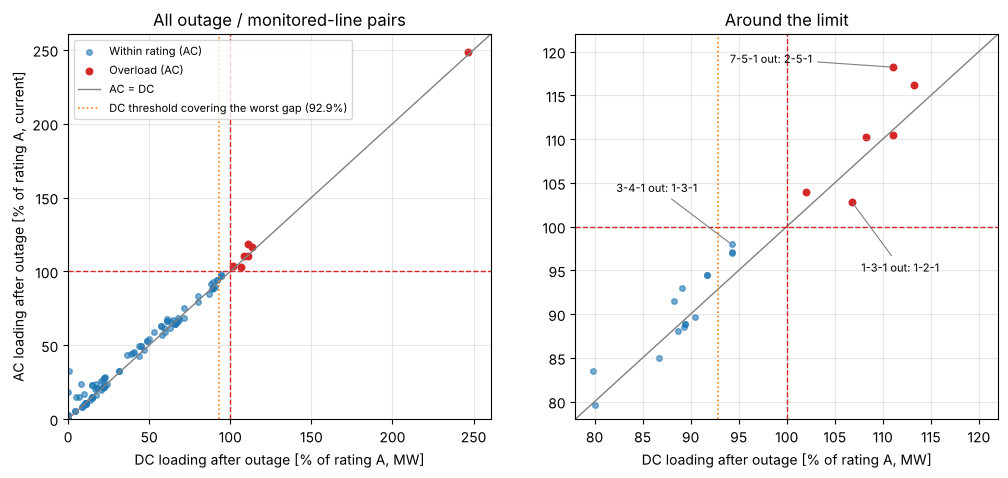

In [9]:
# 9. DC against AC loading for every pair; right panel zooms on the band around the limit
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = max(pairs.DC.max(), pairs["AC current"].max()) * 1.05
for ax, lim in ((axes[0], (0, top)), (axes[1], (78, 122))):
    over = pairs["AC current"] > 100
    ax.scatter(pairs.DC[~over], pairs["AC current"][~over], s=16, color="tab:blue", alpha=0.6, label="Within rating (AC)")
    ax.scatter(pairs.DC[over], pairs["AC current"][over], s=22, color="tab:red", label="Overload (AC)")
    ax.plot(lim, lim, color="gray", lw=1, label="AC = DC")
    ax.axhline(100, color="tab:red", ls="--", lw=1)
    ax.axvline(100, color="tab:red", ls="--", lw=1)
    ax.axvline(threshold, color="tab:orange", ls=":", lw=1.2, label=f"DC threshold covering the worst gap ({threshold:.1f}%)")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("DC loading after outage [% of rating A, MW]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("AC loading after outage [% of rating A, current]")
axes[0].set_title("All outage / monitored-line pairs")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].set_title("Around the limit")
# the largest gap, the closest call DC did not flag, and the one where DC is pessimistic
picks = [near["Gap [pts]"].idxmax(), pairs.loc[pairs.DC <= 100, "AC current"].idxmax(), near["Gap [pts]"].idxmin()]
for i, (dx, dy) in zip(picks, ((-17, 0.5), (-12, 6), (1, -8))):
    r = pairs.loc[i]
    axes[1].annotate(f"{r.Outage} out: {r.Line}", (r.DC, r["AC current"]), xytext=(r.DC + dx, r["AC current"] + dy),
                     fontsize=8, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8))
fig.savefig(IMG / "Week4_ex4_dc_vs_ac_n1_loading.png", dpi=150, bbox_inches="tight")
plt.show()